Please upload train.csv from the Kaggle Store Sales dataset:


Saving train.csv to train.csv
Loaded train.csv -> shape: (3000888, 6)
   id       date  store_nbr      family  sales  onpromotion
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0
1   1 2013-01-01          1   BABY CARE    0.0            0
2   2 2013-01-01          1      BEAUTY    0.0            0
3   3 2013-01-01          1   BEVERAGES    0.0            0
4   4 2013-01-01          1       BOOKS    0.0            0
Sampled shape (for faster training): (84200, 6)


/tmp/ipykernel_3396/3929879964.py:48: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby(["store_nbr", "family"], group_keys=False).apply(add_lag_features)


Shape after lag features + dropna: (82700, 13)
Number of features: 38
Train size: (66200, 38), Test size: (16500, 38), Split date: 2016-09-18 00:00:00
Best alpha: 1

=== Test Set Performance ===
Ridge -> RMSE: 272.34 | MAE: 91.77 | R2: 0.9236
OLS (no regularization) -> RMSE: 272.34 | MAE: 91.77 | R2: 0.9236


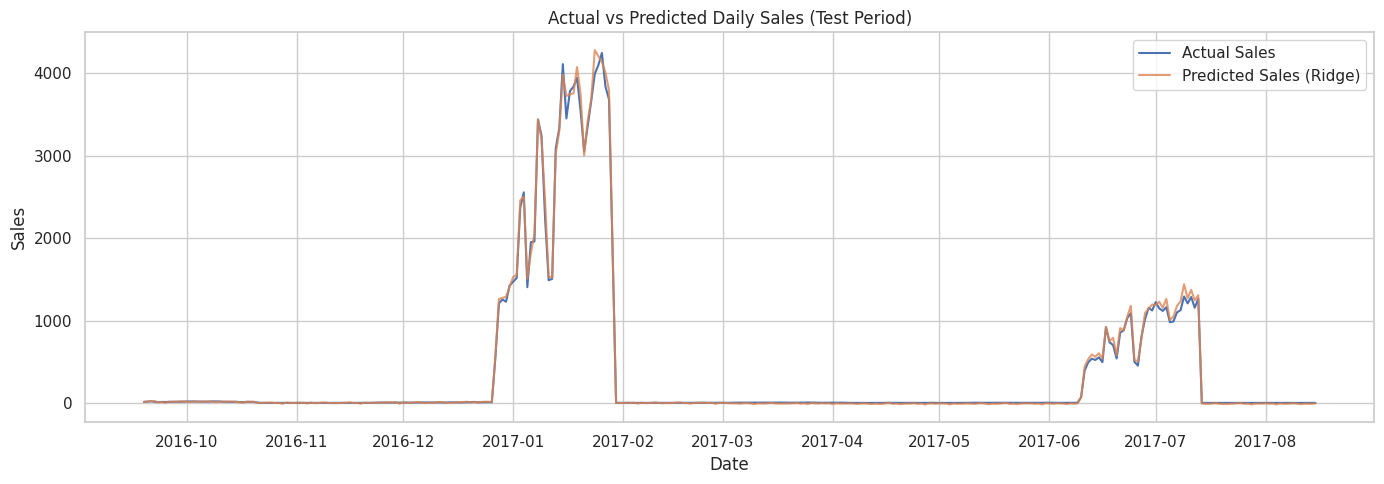

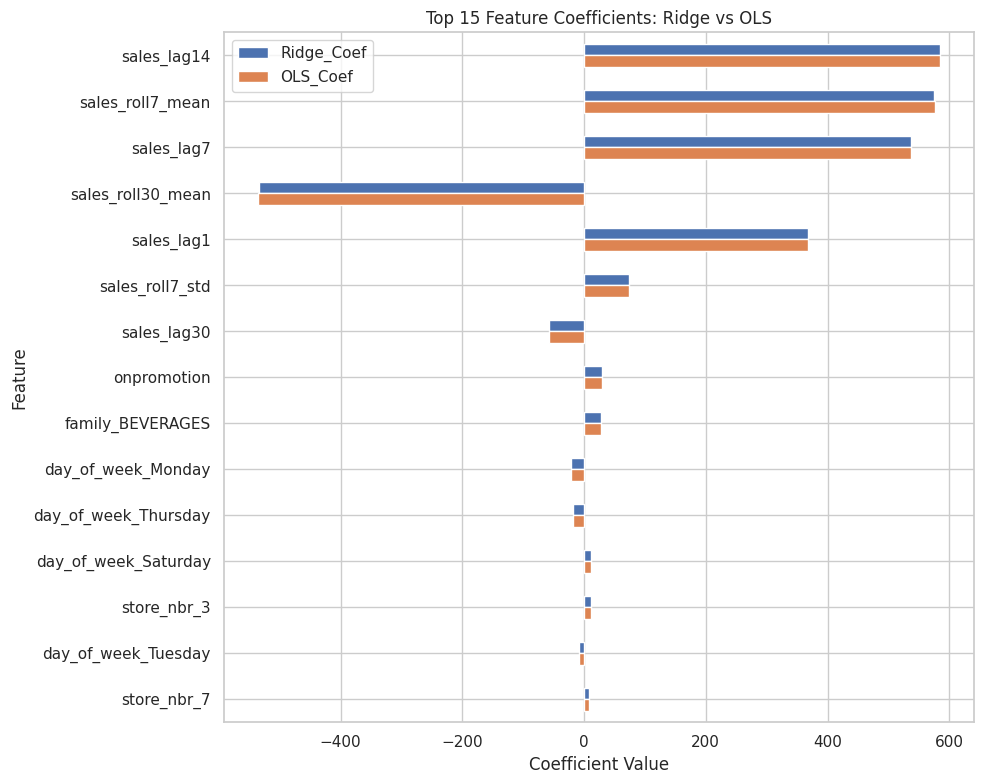


Notice how Ridge shrinks correlated lag/seasonal coefficients
compared to unregularized OLS, reducing overfitting risk.


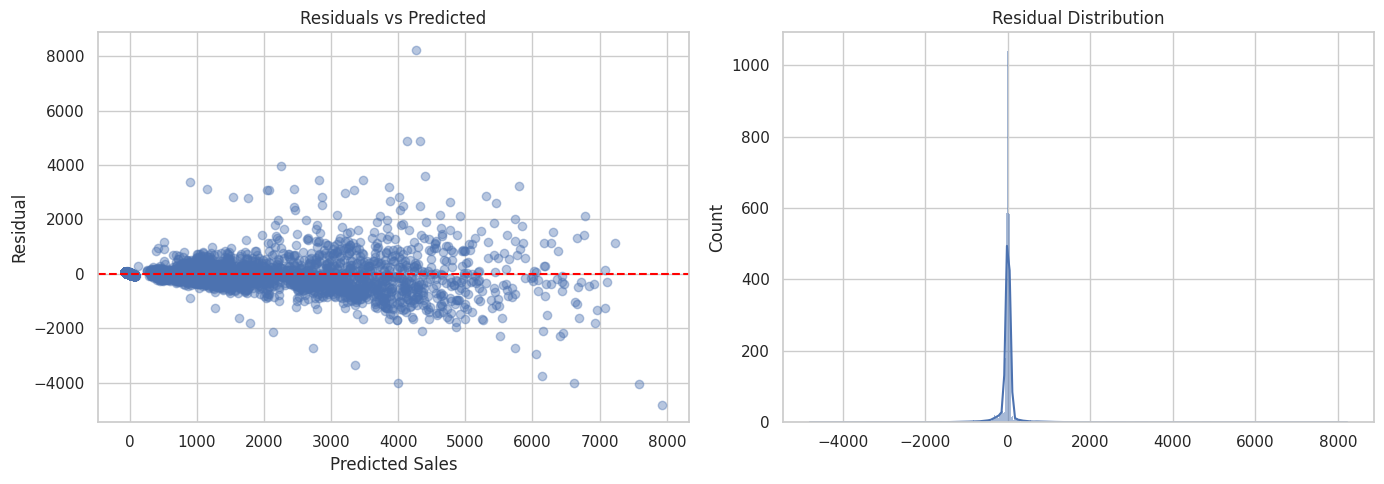

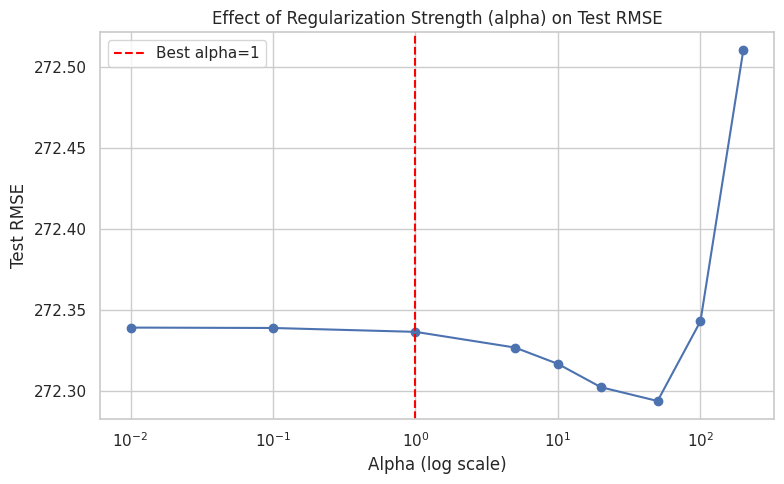

In [ ]:
# ---- 1. Install/Import ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from google.colab import files

sns.set(style="whitegrid")
np.random.seed(42)

# ---- 2. Upload Dataset ----
print("Please upload train.csv from the Kaggle Store Sales dataset:")
uploaded = files.upload()

# Automatically pick the uploaded train file
train_filename = [f for f in uploaded.keys() if "train" in f.lower()][0]
df = pd.read_csv(train_filename, parse_dates=["date"])

print(f"Loaded {train_filename} -> shape: {df.shape}")
print(df.head())

# ---- 3. Basic Cleaning ----
# Kaggle columns: id, date, store_nbr, family, sales, onpromotion
df = df.sort_values(["store_nbr", "family", "date"]).reset_index(drop=True)

# To keep runtime manageable, optionally sample a subset of store-family combos.
SAMPLE_MODE = True
if SAMPLE_MODE:
    top_families = df["family"].unique()[:5]         # first 5 product categories
    top_stores = df["store_nbr"].unique()[:10]        # first 10 stores
    df = df[df["family"].isin(top_families) & df["store_nbr"].isin(top_stores)]
    print(f"Sampled shape (for faster training): {df.shape}")

# ---- 4. Feature Engineering: Lag Features & Rolling Stats ----
def add_lag_features(group):
    group = group.sort_values("date").copy()
    for lag in [1, 7, 14, 30]:
        group[f"sales_lag{lag}"] = group["sales"].shift(lag)
    group["sales_roll7_mean"] = group["sales"].shift(1).rolling(7).mean()
    group["sales_roll7_std"] = group["sales"].shift(1).rolling(7).std()
    group["sales_roll30_mean"] = group["sales"].shift(1).rolling(30).mean()
    return group

df = df.groupby(["store_nbr", "family"], group_keys=False).apply(add_lag_features)
df = df.dropna().reset_index(drop=True)
print(f"Shape after lag features + dropna: {df.shape}")

# ---- 5. Feature Engineering: Seasonal Dummy Variables ----
df["day_of_week"] = df["date"].dt.day_name()
df["month"] = df["date"].dt.month_name()
df["onpromotion"] = df["onpromotion"].fillna(0).astype(int)

df_model = pd.get_dummies(
    df,
    columns=["day_of_week", "month", "family", "store_nbr"],
    drop_first=True
)

drop_cols = [c for c in ["id", "date", "sales"] if c in df_model.columns]
feature_cols = [c for c in df_model.columns if c not in drop_cols]
X = df_model[feature_cols]
y = df_model["sales"]
print(f"Number of features: {len(feature_cols)}")

# ---- 6. Chronological Train/Test Split ----
df_model = df_model.sort_values("date").reset_index(drop=True)
split_date = df_model["date"].quantile(0.8, interpolation="nearest")

train_mask = df_model["date"] <= split_date
test_mask = df_model["date"] > split_date

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
dates_test = df_model.loc[test_mask, "date"]

print(f"Train size: {X_train.shape}, Test size: {X_test.shape}, Split date: {split_date}")

# ---- 7. Feature Scaling ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ---- 8. Hyperparameter Tuning for Ridge (alpha) ----
tscv = TimeSeriesSplit(n_splits=5)
param_grid = {"alpha": [0.01, 0.1, 1, 5, 10, 20, 50, 100]}

ridge_cv = GridSearchCV(
    Ridge(),
    param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_cv.fit(X_train_scaled, y_train)
best_alpha = ridge_cv.best_params_["alpha"]
print(f"Best alpha: {best_alpha}")

# ---- 9. Train Final Ridge Model & Compare with OLS ----
ridge_model = Ridge(alpha=best_alpha)
ridge_model.fit(X_train_scaled, y_train)

ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)
y_pred_ols = ols_model.predict(X_test_scaled)

def evaluate(y_true, y_pred, label):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{label} -> RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.4f}")
    return rmse, mae, r2

print("\n=== Test Set Performance ===")
ridge_metrics = evaluate(y_test, y_pred_ridge, "Ridge")
ols_metrics = evaluate(y_test, y_pred_ols, "OLS (no regularization)")

# ---- 10. Plot: Actual vs Predicted Sales Over Time ----
plot_df = pd.DataFrame({
    "date": dates_test,
    "Actual": y_test.values,
    "Predicted": y_pred_ridge
}).groupby("date").mean().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(plot_df["date"], plot_df["Actual"], label="Actual Sales", linewidth=1.5)
plt.plot(plot_df["date"], plot_df["Predicted"], label="Predicted Sales (Ridge)", linewidth=1.5, alpha=0.8)
plt.title("Actual vs Predicted Daily Sales (Test Period)")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

# ---- 11. Plot: Ridge vs OLS Coefficient Magnitudes ----
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Ridge_Coef": ridge_model.coef_,
    "OLS_Coef": ols_model.coef_
}).sort_values("Ridge_Coef", key=abs, ascending=False)

top_n = coef_df.head(15).set_index("Feature")
top_n[["Ridge_Coef", "OLS_Coef"]].plot(kind="barh", figsize=(10, 8))
plt.title("Top 15 Feature Coefficients: Ridge vs OLS")
plt.xlabel("Coefficient Value")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nNotice how Ridge shrinks correlated lag/seasonal coefficients")
print("compared to unregularized OLS, reducing overfitting risk.")

# ---- 12. Residual Diagnostics ----
residuals = y_test.values - y_pred_ridge

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred_ridge, residuals, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

# ---- 13. Alpha Sensitivity Plot ----
alphas = [0.01, 0.1, 1, 5, 10, 20, 50, 100, 200]
rmses = []
for a in alphas:
    m = Ridge(alpha=a).fit(X_train_scaled, y_train)
    pred = m.predict(X_test_scaled)
    rmses.append(np.sqrt(mean_squared_error(y_test, pred)))

plt.figure(figsize=(8, 5))
plt.plot(alphas, rmses, marker="o")
plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Test RMSE")
plt.title("Effect of Regularization Strength (alpha) on Test RMSE")
plt.axvline(best_alpha, color="red", linestyle="--", label=f"Best alpha={best_alpha}")
plt.legend()
plt.tight_layout()
plt.show()